# Pipeline walkthrough: from drone image to maintenance priority

This notebook walks through the whole pipeline, one step per section, on the project's real
outputs. It does **not** retrain anything: it runs the trained detector on 3 sample images, then
reads the results the pipeline already produced (`outputs/`). It runs in under a minute on a
laptop CPU.

`drone image → detected distress → GPS location → hotspots → segment priority → predicted condition → SQL`

> **What's real vs. simulated**: the images, the detector, the street network (OpenStreetMap) and
> the condition data (City of Montréal) are real. The GPS position of each photo is **simulated**
> (no real flight was available) — see the README's *Data* section.

In [1]:
# --- Setup ---------------------------------------------------------------
# The notebook lives in notebooks/, but every path in the project is relative
# to the repo root (e.g. "outputs/..."), so we move there first.
import os, sys, json, sqlite3
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))  # lets us import the project's own code (src/...)

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import yaml
import contextily as ctx  # downloads basemap tiles (needs internet)

with open("configs/config.yaml", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)  # the single source of truth for every parameter

METRIC_CRS = cfg["geo"]["metric_crs"]  # UTM 18N: coordinates in metres, so distances make sense
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

## 1. Detect distress on drone images (YOLO)

A **YOLO11n** detector, fine-tuned on the UAV-PDD2023 drone dataset (6 distress classes), looks
at each image and returns boxes: *where* the damage is, *what* it is, and *how confident* the
model is. We keep boxes above a confidence of 0.25.

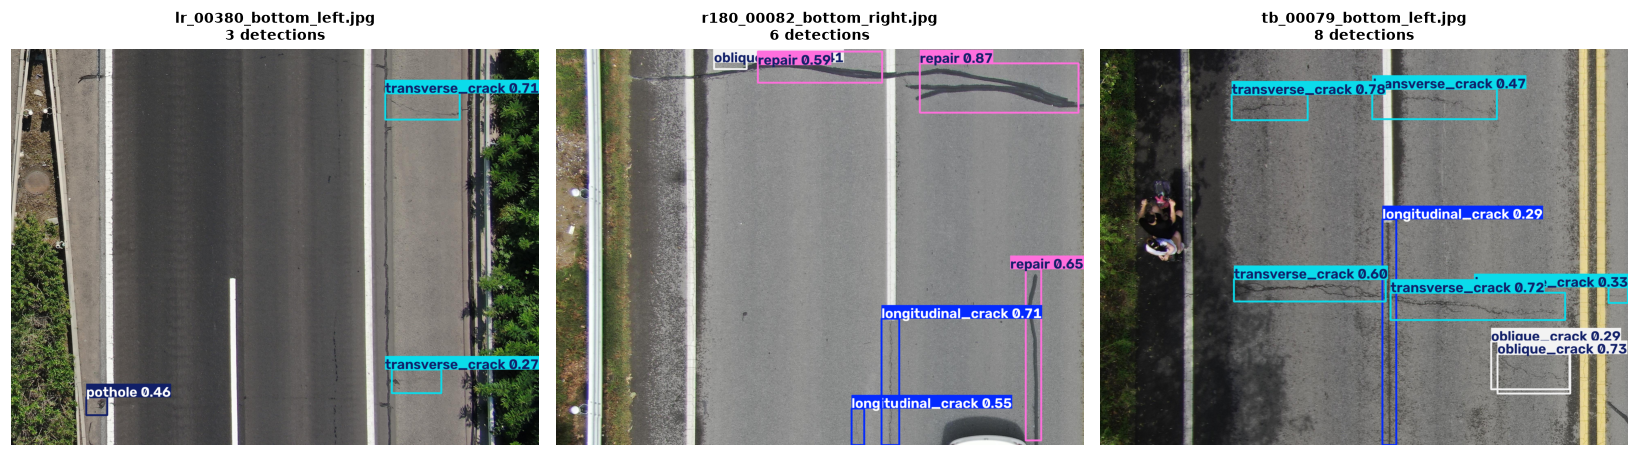

,image,class,confidence
0,lr_00380_bottom_left.jpg,transverse_crack,0.71
1,lr_00380_bottom_left.jpg,pothole,0.46
2,lr_00380_bottom_left.jpg,transverse_crack,0.27
3,r180_00082_bottom_right.jpg,repair,0.87
4,r180_00082_bottom_right.jpg,longitudinal_crack,0.71
5,r180_00082_bottom_right.jpg,repair,0.65
6,r180_00082_bottom_right.jpg,repair,0.59
7,r180_00082_bottom_right.jpg,longitudinal_crack,0.55
8,r180_00082_bottom_right.jpg,oblique_crack,0.41
9,tb_00079_bottom_left.jpg,transverse_crack,0.78


In [2]:
from ultralytics import YOLO

model = YOLO(cfg["inference"]["weights"])  # the trained weights (5 MB)
sample_images = sorted(Path("assets/sample_images").glob("*.jpg"))

# predict() returns one result per image; conf filters out weak guesses.
results = model.predict([str(p) for p in sample_images], conf=cfg["inference"]["conf"], verbose=False)

fig, axes = plt.subplots(1, len(results), figsize=(15, 5))
for ax, path, r in zip(axes, sample_images, results):
    ax.imshow(r.plot()[:, :, ::-1])  # r.plot() draws the boxes; [:, :, ::-1] converts BGR -> RGB
    ax.set_title(f"{path.name}\n{len(r.boxes)} detections", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

# The same information as a table: one row per detected box.
rows = [
    {"image": path.name, "class": r.names[int(b.cls)], "confidence": round(float(b.conf), 2)}
    for path, r in zip(sample_images, results) for b in r.boxes
]
pd.DataFrame(rows)

**How good is the detector?** Metrics on the validation set after 50 epochs (read from the
training log, not typed by hand):

In [3]:
log = pd.read_csv("models/baseline/results.csv")
log.columns = [c.strip() for c in log.columns]
last = log.iloc[-1]  # the final epoch
pd.Series({
    "precision": last["metrics/precision(B)"],   # of the boxes predicted, how many are real damage
    "recall": last["metrics/recall(B)"],         # of the real damage, how much was found
    "mAP50": last["metrics/mAP50(B)"],           # overall detection quality (standard YOLO metric)
    "mAP50-95": last["metrics/mAP50-95(B)"],     # same, but with stricter box overlap
}).round(3).to_frame("value")

,value
precision,0.563
recall,0.505
mAP50,0.472
mAP50-95,0.222


Modest but honest for a *nano* model trained on a free GPU: it finds about half the damage.
Thin cracks are hard to see from the air, and the rarest classes (potholes) have very few
training examples.

## 2. Put each detection on the map (georeferencing)

Each drone photo carries a GPS position in its EXIF metadata. Every detection inherits the
position of the photo it was found on. Here is the GPS read directly from one sample image:

In [4]:
from src.geo.georeference import exif_latlon  # the project's own EXIF reader

for p in sample_images:
    lat, lon = exif_latlon(p)
    print(f"{p.name:32s} lat={lat:.5f}  lon={lon:.5f}")

lr_00380_bottom_left.jpg         lat=45.50949  lon=-73.61720
r180_00082_bottom_right.jpg      lat=45.50993  lon=-73.61573
tb_00079_bottom_left.jpg         lat=45.50521  lon=-73.61709


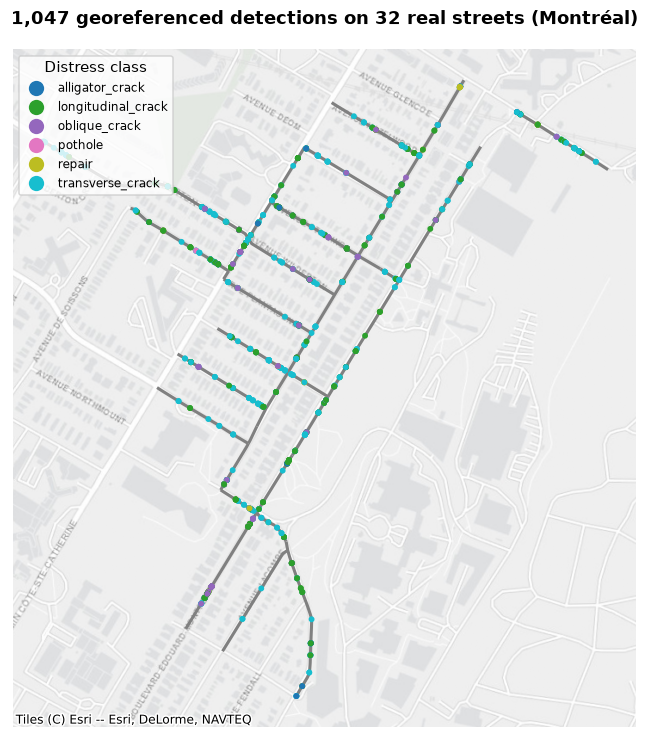

In [5]:
# All 1,047 detections from the full survey (244 images), already georeferenced by the pipeline.
det = pd.read_csv("outputs/detections/detections_segmented.csv")
points = gpd.GeoDataFrame(det, geometry=gpd.points_from_xy(det.lon, det.lat), crs="EPSG:4326").to_crs(METRIC_CRS)

segments = gpd.read_file("outputs/segment_priority.gpkg", layer="segment_priority").to_crs(METRIC_CRS)

fig, ax = plt.subplots(figsize=(8, 8))
segments.plot(ax=ax, color="grey", linewidth=2, zorder=2)
points.plot(ax=ax, column="class_name", markersize=8, legend=True, zorder=3,
            legend_kwds={"loc": "upper left", "fontsize": 8, "title": "Distress class"})
ctx.add_basemap(ax, crs=METRIC_CRS, source=ctx.providers.Esri.WorldGrayCanvas, zorder=1)
ax.set_title("1,047 georeferenced detections on 32 real streets (Montréal)")
ax.set_axis_off()
plt.show()

## 3. Find damage hotspots (DBSCAN)

Individual points are noisy. **DBSCAN** groups detections that are close together: a hotspot is at
least `min_samples = 3` detections within `eps = 20 m` of each other. Isolated points are treated
as noise. Unlike k-means, DBSCAN does not need to know the number of clusters in advance, and a
hotspot can cross a street boundary.

84 hotspots found


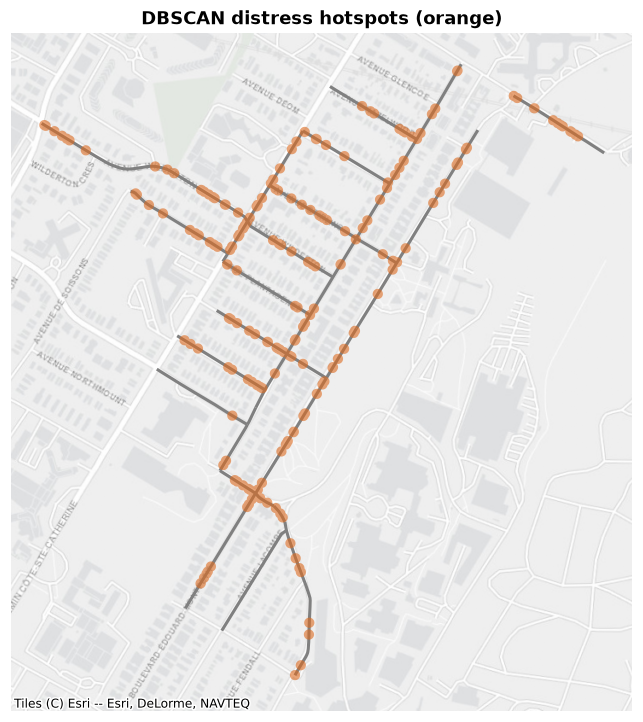

,hotspot_id,n_detections,dominant_class
10,10,75,longitudinal_crack
26,26,51,longitudinal_crack
2,2,37,longitudinal_crack
4,4,31,transverse_crack
6,6,31,longitudinal_crack


In [6]:
hotspots = gpd.read_file("outputs/segment_priority.gpkg", layer="distress_hotspots").to_crs(METRIC_CRS)
print(f"{len(hotspots)} hotspots found")

fig, ax = plt.subplots(figsize=(8, 8))
segments.plot(ax=ax, color="grey", linewidth=2, zorder=2)
hotspots.plot(ax=ax, color="#dd6b20", alpha=0.6, zorder=3)
ctx.add_basemap(ax, crs=METRIC_CRS, source=ctx.providers.Esri.WorldGrayCanvas, zorder=1)
ax.set_title("DBSCAN distress hotspots (orange)")
ax.set_axis_off()
plt.show()

hotspots.drop(columns="geometry").sort_values("n_detections", ascending=False).head()

## 4. Score each street segment

Each detection is snapped to its nearest street (max 15 m). A segment's **priority score** is
the sum of its detections' severity, weighted by the model's confidence:

$$\text{priority} = \sum_{\text{detections}} \text{severity(class)} \times \text{confidence}$$

with severity going from 5 (pothole) down to 1 (repair). It's deliberately simple, so it's easy to
explain to a city's maintenance team.

Severity weights: {'pothole': 5, 'alligator_crack': 4, 'transverse_crack': 3, 'longitudinal_crack': 2, 'oblique_crack': 2, 'repair': 1}


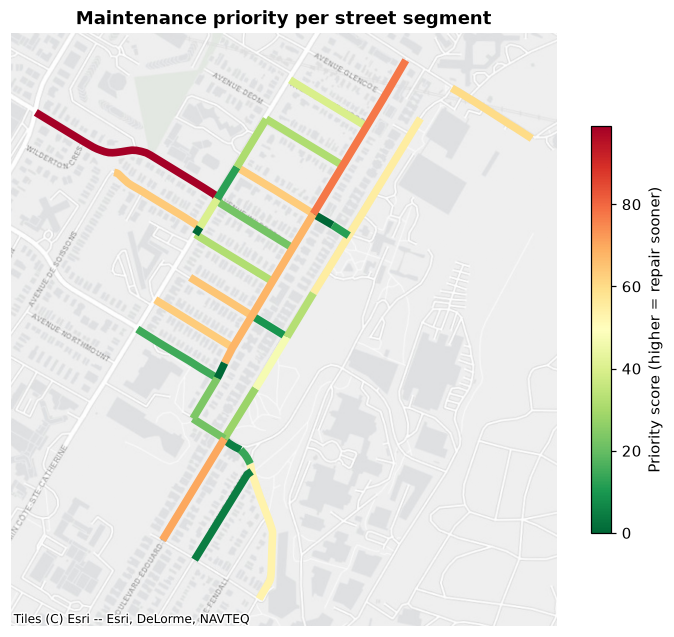

,seg_id,osm_way_id,name,priority_score,n_detections,worst_class,priority_rank
12,12,68920348,Avenue Wilderton,98.9561,85,alligator_crack,1
31,31,1431935104,Avenue Willowdale,77.5544,73,pothole,2
21,21,464720532,Boulevard Édouard-Montpetit,70.0637,80,alligator_crack,3
27,27,723265933,Avenue Willowdale,67.7891,66,transverse_crack,4
2,2,19936423,Avenue Woodbury,64.6260,50,alligator_crack,5


In [7]:
print("Severity weights:", cfg["geo"]["severity_weights"])

fig, ax = plt.subplots(figsize=(8, 8))
segments.plot(ax=ax, column="priority_score", cmap="RdYlGn_r", linewidth=5, legend=True, zorder=2,
              legend_kwds={"label": "Priority score (higher = repair sooner)", "shrink": 0.6})
ctx.add_basemap(ax, crs=METRIC_CRS, source=ctx.providers.Esri.WorldGrayCanvas, zorder=1)
ax.set_title("Maintenance priority per street segment")
ax.set_axis_off()
plt.show()

segments.drop(columns="geometry").sort_values("priority_rank").head(5)

## 5. Estimate condition where the drone didn't fly (scikit-learn)

A drone can't survey a whole city every year. A second model predicts a segment's **Pavement
Condition Index** (PCI, 0-100, higher = better) from attributes the city already has everywhere:
length, borough, roughness (IRI), pavement age and material. It's trained on **~16,000 real
segments** from the City of Montréal's own pavement survey.

In [8]:
with open("outputs/segment_model/metrics.json") as f:
    metrics = json.load(f)
print("Cross-validation R² per model:", {k: round(v, 3) for k, v in metrics["cv_r2"].items()})
print("Held-out test set:", {k: round(v, 3) for k, v in metrics["test"].items()})

Cross-validation R² per model: {'random_forest': 0.345, 'gradient_boosting': 0.37}
Held-out test set: {'mae': 14.099, 'rmse': 17.48, 'r2': 0.354}


**R² = 0.35**: the model explains about a third of the variation in PCI, with a typical error of
±14 points. This is a real, modest result: pavement condition also depends on traffic loads,
freeze-thaw cycles and maintenance history, which aren't in open data.

Now the most interesting check: on our 32 demo streets, we compare the **drone score**, the
**model's prediction** and the **city's real, measured PCI**.

26 of 32 demo segments matched a real Montréal survey segment


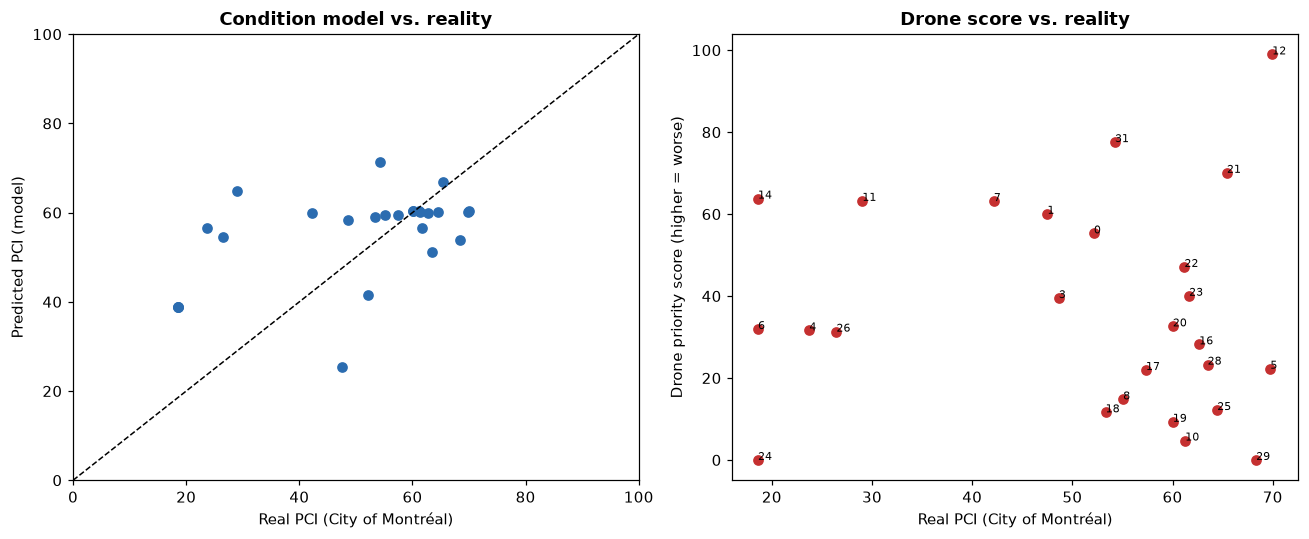

,real_indice_pci,predicted_score,drone_priority_score
real_indice_pci,1.00,0.48,-0.13
predicted_score,0.48,1.00,0.25
drone_priority_score,-0.13,0.25,1.00


In [9]:
cmp = pd.read_csv("outputs/segment_model/surveyed_vs_predicted.csv")
print(f"{len(cmp)} of 32 demo segments matched a real Montréal survey segment")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Left: does the model's predicted PCI agree with the real PCI? (perfect = on the diagonal)
ax1.scatter(cmp.real_indice_pci, cmp.predicted_score, color="#2b6cb0")
ax1.plot([0, 100], [0, 100], "k--", linewidth=1)
ax1.set(xlabel="Real PCI (City of Montréal)", ylabel="Predicted PCI (model)",
        title="Condition model vs. reality", xlim=(0, 100), ylim=(0, 100))

# Right: do streets with more drone-detected damage really have a worse PCI?
ax2.scatter(cmp.real_indice_pci, cmp.drone_priority_score, color="#c53030")
ax2.set(xlabel="Real PCI (City of Montréal)", ylabel="Drone priority score (higher = worse)",
        title="Drone score vs. reality")
for _, r in cmp.iterrows():
    ax2.annotate(int(r.seg_id), (r.real_indice_pci, r.drone_priority_score), fontsize=7)
plt.tight_layout()
plt.show()

corr = cmp[["real_indice_pci", "predicted_score", "drone_priority_score"]].corr(method="spearman")
corr.round(2)

**Reading these plots honestly**: on the left, the model's predictions are compressed toward
the city average (~60), so it overestimates the worst streets. That's the typical behaviour of a
model with R² ≈ 0.35. On the right, the drone score is based on *simulated* photo positions (photos
are scattered randomly on the streets), so it is not expected to track the real PCI, and indeed
its rank correlation with the real PCI is about zero (-0.13), while the condition model's is 0.48.
Segment 24 is
the clearest case: zero drone detections, yet a real PCI of 18.6, tied for the worst on the
network. This is
exactly why a real deployment would need real flights, and why the city's measured data is kept
as an independent check rather than mixed into the score.

## 6. Query the results with SQL

Everything is also loaded into a small SQLite database (`outputs/pavement.db`, schema in
`sql/schema.sql`) with three tables: `segments`, `detections`, `segment_scores`. This is how a city
team would plug the results into its own tools.

In [10]:
con = sqlite3.connect("outputs/pavement.db")

# The 5 segments to repair first, with their borough and the city's real PCI next to our score.
pd.read_sql("""
    SELECT s.seg_id, g.arrondissement, s.n_detections, s.worst_class,
           ROUND(s.priority_score, 1)  AS drone_score,
           ROUND(s.real_indice_pci, 1) AS real_pci
    FROM segment_scores AS s
    JOIN segments       AS g ON g.seg_id = s.seg_id
    ORDER BY s.priority_rank
    LIMIT 5
""", con)

,seg_id,arrondissement,n_detections,worst_class,drone_score,real_pci
0,12,Côte-des-Neiges-Notre-Dame-de-Grâce,85,alligator_crack,99.0,70.0
1,31,Outremont,73,pothole,77.6,54.3
2,21,Côte-des-Neiges-Notre-Dame-de-Grâce,80,alligator_crack,70.1,65.4
3,27,NaN,66,transverse_crack,67.8,NaN
4,2,NaN,50,alligator_crack,64.6,NaN


In [11]:
# Which kind of damage dominates the survey?
pd.read_sql("""
    SELECT class_name, COUNT(*) AS n, ROUND(AVG(confidence), 2) AS avg_conf
    FROM detections
    GROUP BY class_name
    ORDER BY n DESC
""", con)

,class_name,n,avg_conf
0,transverse_crack,425,0.48
1,longitudinal_crack,383,0.41
2,oblique_crack,155,0.43
3,repair,43,0.59
4,alligator_crack,37,0.46
5,pothole,4,0.34


## Takeaways

- **End to end**: raw drone images become a ranked list of streets to repair, as a map (QGIS
  GeoPackage) and as a database.
- **Two ML engines, each for its data type**: deep learning (YOLO) on pixels, classic ML
  (gradient boosting) on tabular city data.
- **Real data wherever it exists**: street network, condition training data and ground truth are
  real; only the flight GPS is simulated, and the notebook shows where that limits the conclusions.

**Next steps for a real deployment**: a real geotagged flight (or an orthomosaic), a larger and
rebalanced training set for rare classes like potholes, and historical PCI as a feature for the
condition model.